# I. Portada

| Campo | Informacion |
|---|---|
| Nombre | Jesus Pascual Garay Ordaz |
| Matricula | 306025 |
| Programa academico | MIC |
| Materia | Machine Learning |
| Nombre de la actividad | proyecto-final: entrenamiento de modelos para la interfaz |
| Docente | Olanda Prieto Ordaz |
| Fecha | 1 de noviembre de 2026 |

# II. Introduccion

Este notebook es la primera parte del proyecto final y entrena los modelos que usara la interfaz en Streamlit. El problema es el mismo de los proyectos F_1 y F_2: identificar a los hombres adultos con deficiencia de testosterona (testosterona total menor a 300 ng/dL) a partir de 13 variables clinicas, hormonales y de estilo de vida del NHANES 2021 a 2023, con 2514 hombres y un 22.2% de casos positivos.

Se entrenan los cuatro modelos que se pidieron para la implementacion: **Regresion Logistica, SVM, Random Forest y XGBoost**. Cada uno sigue exactamente el mismo procedimiento, la misma particion 80/20 estratificada con semilla 42 de F_1 y F_2, el mismo preprocesamiento dentro de un Pipeline, busqueda de hiperparametros con validacion cruzada estratificada de 5 folds sobre Train usando ROC AUC, y eleccion del umbral de decision con las predicciones fuera de muestra (OOF) maximizando F2, que da mas peso al recall, igual que en F_1. Test se usa una sola vez al final, y los modelos se guardan entrenados solo con Train para que las metricas reportadas sigan siendo validas.

Los Pipelines guardados reciben directamente las 13 variables tal como las captura la interfaz, con las categoricas en texto, por lo que usan solo clases de scikit-learn y XGBoost y se pueden cargar sin este notebook.

---
# Fase 1. Datos y particion

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
)
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
import sklearn, xgboost
from sklearn import set_config

set_config(display="text")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Misma semilla que en F_1 y F_2
RANDOM_STATE = 42
CARPETA_MODELOS = Path("modelos")
CARPETA_MODELOS.mkdir(exist_ok=True)

In [2]:
# Mismo CSV del proyecto F_1 y F_2
df = pd.read_csv("nhanes_testosterona_2021_2023.csv")

# Los nombres originales son codigos de NHANES, se cambian por nombres descriptivos como en F_1 y F_2
nombres = {
    "SEQN": "id_participante", "RIDAGEYR": "edad", "BMXBMI": "imc", "BMXWAIST": "cintura",
    "LBXSHBG": "shbg", "LBXEST": "estradiol", "LBXLUH": "lh", "LBXFSH": "fsh",
    "DIQ010": "diabetes", "BPQ020": "hipertension", "SMQ020": "fumador",
    "ALQ130": "tragos_por_dia", "RIDRETH3": "raza_etnia", "DMDEDUC2": "escolaridad",
    "LBXTST": "testosterona_total",
}
df = df.rename(columns=nombres)

display(pd.DataFrame({"Filas": [df.shape[0]], "Columnas": [df.shape[1]]}, index=["Dataset"]))
clases = df["deficiencia_testosterona"].map({0: "Normal", 1: "Deficiencia"})
display(pd.DataFrame({"Hombres": clases.value_counts(), "Proporcion": clases.value_counts(normalize=True).round(3)}))

,Filas,Columnas
Dataset,2514,16


,Hombres,Proporcion
deficiencia_testosterona,,
Normal,1955,0.778
Deficiencia,559,0.222


In [3]:
y = df["deficiencia_testosterona"].astype(int)

# Se quitan el identificador, la testosterona cruda (con ella se calcula el objetivo, seria fuga) y el objetivo
X = df.drop(columns=["id_participante", "testosterona_total", "deficiencia_testosterona"])

num_cols = ["edad", "imc", "cintura", "shbg", "estradiol", "lh", "fsh", "tragos_por_dia"]
cat_cols = ["diabetes", "hipertension", "fumador", "raza_etnia", "escolaridad"]

# Particion 80% Train y 20% Test, estratificada, igual que en F_1 y F_2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
display(pd.DataFrame({
    "Filas": [len(X_train), len(X_test)],
    "Columnas": [X_train.shape[1], X_test.shape[1]],
    "% de deficiencia": [100 * y_train.mean(), 100 * y_test.mean()],
}, index=["Train", "Test"]).round(2))

,Filas,Columnas,% de deficiencia
Train,2011,13,22.23
Test,503,13,22.27


In [4]:
# Regla fija del F_1: los codigos de "rehuso" y "no sabe" se pasan a faltante
# No se aprende nada de los datos, por eso se aplica igual a Train y a Test
codigos_especiales = {"hipertension": [7, 9], "fumador": [7, 9], "escolaridad": [7, 9], "tragos_por_dia": [777, 999]}
for col, codigos in codigos_especiales.items():
    X_train[col] = X_train[col].replace(codigos, np.nan)
    X_test[col] = X_test[col].replace(codigos, np.nan)

# Regla fija del F_1: los codigos de las categoricas se cambian por su significado
etiquetas = {
    "diabetes": {1: "Si", 2: "No", 3: "Prediabetes"},
    "hipertension": {1: "Si", 2: "No"},
    "fumador": {1: "Si", 2: "No"},
    "raza_etnia": {1: "Mexico americano", 2: "Otro hispano", 3: "Blanco no hispano",
                   4: "Negro no hispano", 6: "Asiatico no hispano", 7: "Otra o multirracial"},
    "escolaridad": {1: "Menos de 9 grado", 2: "9 a 11 grado", 3: "Preparatoria completa",
                    4: "Universidad incompleta", 5: "Universidad completa o mas"},
}
for col, mapa in etiquetas.items():
    X_train[col] = X_train[col].map(mapa)
    X_test[col] = X_test[col].map(mapa)

display(pd.DataFrame({
    "Faltantes en Train": X_train.isna().sum(),
    "Porcentaje (%)": (X_train.isna().mean() * 100).round(1),
}).sort_values("Faltantes en Train", ascending=False))

,Faltantes en Train,Porcentaje (%)
tragos_por_dia,249,12.4
cintura,75,3.7
imc,24,1.2
estradiol,10,0.5
fumador,2,0.1
hipertension,1,0.0
edad,0,0.0
shbg,0,0.0
lh,0,0.0
diabetes,0,0.0


---
# Fase 2. Pipeline de preprocesamiento

Es el mismo de F_1 y F_2: las numericas se imputan con la mediana y se escalan, las categoricas se imputan con la moda y se codifican con OneHotEncoder. Todo vive dentro del Pipeline, por lo que se ajusta solo con los datos de entrenamiento de cada fold y la interfaz puede dejar una variable vacia, que el Pipeline imputa con la mediana de Train.

In [5]:
def crear_preprocesador():
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])


def construir_pipeline(modelo):
    """Pipeline = Preprocesamiento + Modelo. Se ajusta solo con los datos de entrenamiento."""
    return Pipeline([("prep", crear_preprocesador()), ("modelo", modelo)])


# Esquema de validacion y metricas, igual que en F_1 y F_2
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Cociente entre clases negativas y positivas, para el peso de la clase positiva en XGBoost
peso_positivos = round(float((y_train == 0).sum() / (y_train == 1).sum()), 3)

# Modelos con parametros por defecto
modelos_defecto = {
    "Regresion Logistica": LogisticRegression(max_iter=1000),
    "SVM": SVC(kernel="rbf"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, eval_metric="logloss", random_state=RANDOM_STATE,
                             n_jobs=1, verbosity=0),
}
print("Peso de la clase positiva:", peso_positivos)

Peso de la clase positiva: 3.499


---
# Fase 3. Modelos con parametros por defecto

Antes de optimizar se mide cada modelo con validacion cruzada de 5 folds para tener una referencia.

In [6]:
def resumir_cv(nombre, res):
    fila = {"Modelo": nombre}
    for m in metricas_cv:
        fila[f"{m}"] = res[f"test_{m}"].mean()
        fila[f"{m}_std"] = res[f"test_{m}"].std()
    fila["roc_auc_train"] = res["train_roc_auc"].mean()
    return fila

filas = []
for nombre, modelo in modelos_defecto.items():
    res = cross_validate(construir_pipeline(modelo), X_train, y_train, cv=cv, scoring=metricas_cv,
                         return_train_score=True, n_jobs=-1)
    filas.append(resumir_cv(nombre, res))

tabla_defecto = pd.DataFrame(filas).set_index("Modelo")
display(tabla_defecto[["accuracy", "precision", "recall", "f1", "roc_auc", "roc_auc_std", "roc_auc_train"]].round(4))

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,roc_auc_train
Modelo,,,,,,,
Regresion Logistica,0.8409,0.6961,0.5077,0.5839,0.8657,0.0155,0.8761
SVM,0.8414,0.7159,0.4808,0.5728,0.8774,0.0197,0.9323
Random Forest,0.8543,0.7561,0.5100,0.6083,0.8903,0.0136,1.0000
XGBoost,0.8334,0.6449,0.5616,0.6000,0.8644,0.0158,1.0000


**Análisis de los modelos por defecto**

Con parámetros por defecto los cuatro modelos quedan en un rango de ROC AUC de 0.864 a 0.890, con Random Forest arriba (0.890) y XGBoost y Regresión Logística abajo (0.864 y 0.866), pero todos comparten el mismo problema que se vio en F_1 y F_2, ya que el recall se queda entre 0.48 y 0.56, es decir que con el umbral estándar de 0.5 detectan a solo la mitad de los hombres con deficiencia porque ninguno compensa el desbalance de clases. Random Forest y XGBoost además llegan a un ROC AUC de 1.000 en los folds de entrenamiento contra 0.890 y 0.864 en validación, lo que muestra que memorizan Train y que van a necesitar regularización.

Esto confirma que la optimización y la elección del umbral son lo que realmente cambia el resultado.

---
# Fase 4. Optimizacion de hiperparametros

Para cada modelo se busca con `GridSearchCV` (5 folds estratificados, solo Train) maximizando ROC AUC, que es la metrica de F_1 y F_2. Se incluye `class_weight` (o el peso de la clase positiva en XGBoost) porque la clase positiva es solo el 22.2% y en F_1 y F_2 fue lo que mas cambio el recall. Las rejillas de Regresion Logistica y SVM son las mismas de F_1 y F_2.

In [7]:
scoring_grid = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1"}

def buscar(pipeline, rejilla):
    grid = GridSearchCV(pipeline, rejilla, cv=cv, scoring=scoring_grid, refit="roc_auc",
                        n_jobs=-1, return_train_score=True)
    grid.fit(X_train, y_train)
    return grid

def top_resultados(grid, columnas, n=5):
    r = pd.DataFrame(grid.cv_results_)
    tabla = pd.DataFrame({c.replace("param_modelo__", ""): r[c].astype(str) for c in columnas})
    tabla["roc_auc"] = r["mean_test_roc_auc"]
    tabla["roc_auc_std"] = r["std_test_roc_auc"]
    tabla["roc_auc_train"] = r["mean_train_roc_auc"]
    tabla["recall"] = r["mean_test_recall"]
    return tabla.sort_values("roc_auc", ascending=False).head(n).reset_index(drop=True).round(4)

grids = {}

In [8]:
# Regresion Logistica: misma rejilla de F_1, pero con l1_ratio en lugar de penalty (penalty esta obsoleto
# en scikit-learn 1.8 y posteriores): l1_ratio = 0 equivale a la penalizacion L2 y l1_ratio = 1 a la L1
rejilla_lr = {
    "modelo__C": [0.01, 0.1, 1, 10, 100],
    "modelo__l1_ratio": [0, 1],
    "modelo__class_weight": [None, "balanced"],
}
grids["Regresion Logistica"] = buscar(
    construir_pipeline(LogisticRegression(solver="liblinear", max_iter=1000)), rejilla_lr)
g = grids["Regresion Logistica"]
print("Mejores hiperparametros:", {k.replace("modelo__", ""): v for k, v in g.best_params_.items()})
display(top_resultados(g, ["param_modelo__C", "param_modelo__l1_ratio", "param_modelo__class_weight"]))

Mejores hiperparametros: {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 1}


,C,l1_ratio,class_weight,roc_auc,roc_auc_std,roc_auc_train,recall
0,0.1,1,balanced,0.8684,0.0186,0.8732,0.8389
1,0.1,1,NaN,0.8682,0.0173,0.8730,0.4606
2,0.1,0,NaN,0.8660,0.0167,0.8749,0.4540
3,1.0,1,NaN,0.8660,0.0159,0.8759,0.4965
4,1.0,0,NaN,0.8658,0.0156,0.8761,0.5077


In [9]:
# SVM RBF: misma rejilla de F_2 (sin probability durante la busqueda, el ROC AUC usa decision_function)
rejilla_svm = {
    "modelo__C": [0.01, 0.1, 1, 10, 100],
    "modelo__gamma": ["scale", 0.001, 0.01, 0.1, 1, 10],
    "modelo__class_weight": [None, "balanced"],
}
grids["SVM"] = buscar(construir_pipeline(SVC(kernel="rbf")), rejilla_svm)
g = grids["SVM"]
print("Mejores hiperparametros:", {k.replace("modelo__", ""): v for k, v in g.best_params_.items()})
display(top_resultados(g, ["param_modelo__C", "param_modelo__gamma", "param_modelo__class_weight"]))

Mejores hiperparametros: {'C': 10, 'class_weight': 'balanced', 'gamma': 0.01}


,C,gamma,class_weight,roc_auc,roc_auc_std,roc_auc_train,recall
0,10.0,0.01,balanced,0.8842,0.0222,0.9119,0.8344
1,1.0,scale,balanced,0.8838,0.0158,0.9409,0.8277
2,1.0,0.1,balanced,0.8819,0.0146,0.9482,0.8120
3,10.0,0.01,NaN,0.8816,0.0216,0.9072,0.5011
4,100.0,0.01,NaN,0.8808,0.0229,0.9330,0.5637


In [10]:
# Random Forest: profundidad, tamano minimo de hoja, variables por division y peso de clases
rejilla_rf = {
    "modelo__max_depth": [None, 5, 10],
    "modelo__min_samples_leaf": [1, 3, 5, 10],
    "modelo__max_features": ["sqrt", 0.5],
    "modelo__class_weight": [None, "balanced"],
}
grids["Random Forest"] = buscar(
    construir_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)), rejilla_rf)
g = grids["Random Forest"]
print("Mejores hiperparametros:", {k.replace("modelo__", ""): v for k, v in g.best_params_.items()})
display(top_resultados(g, ["param_modelo__max_depth", "param_modelo__min_samples_leaf",
                           "param_modelo__max_features", "param_modelo__class_weight"]))

Mejores hiperparametros: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3}


,max_depth,min_samples_leaf,max_features,class_weight,roc_auc,roc_auc_std,roc_auc_train,recall
0,NaN,3,0.5,balanced,0.8938,0.0083,0.9985,0.7717
1,10,5,0.5,balanced,0.8932,0.0091,0.9875,0.8075
2,NaN,5,0.5,balanced,0.8930,0.0084,0.9890,0.8075
3,10,5,0.5,NaN,0.8929,0.0085,0.9826,0.5502
4,NaN,3,0.5,NaN,0.8927,0.0102,0.9967,0.5748


In [11]:
# XGBoost: numero de arboles, tasa de aprendizaje, profundidad, muestreo y peso de la clase positiva
rejilla_xgb = {
    "modelo__n_estimators": [100, 300],
    "modelo__learning_rate": [0.03, 0.1],
    "modelo__max_depth": [2, 3, 5],
    "modelo__subsample": [0.7, 1.0],
    "modelo__colsample_bytree": [0.7, 1.0],
    "modelo__scale_pos_weight": [1, peso_positivos],
}
grids["XGBoost"] = buscar(
    construir_pipeline(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1, verbosity=0)),
    rejilla_xgb)
g = grids["XGBoost"]
print("Mejores hiperparametros:", {k.replace("modelo__", ""): v for k, v in g.best_params_.items()})
display(top_resultados(g, ["param_modelo__n_estimators", "param_modelo__learning_rate", "param_modelo__max_depth",
                           "param_modelo__subsample", "param_modelo__colsample_bytree",
                           "param_modelo__scale_pos_weight"]))

Mejores hiperparametros: {'colsample_bytree': 0.7, 'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'scale_pos_weight': 1, 'subsample': 0.7}


,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,scale_pos_weight,roc_auc,roc_auc_std,roc_auc_train,recall
0,300,0.03,2,0.7,0.7,1.0,0.8957,0.0138,0.9341,0.5525
1,100,0.1,2,0.7,1.0,1.0,0.8953,0.0153,0.9364,0.5614
2,300,0.03,2,0.7,1.0,1.0,0.8950,0.0133,0.9354,0.5615
3,100,0.03,5,0.7,1.0,1.0,0.8946,0.0140,0.9705,0.5434
4,100,0.1,2,1.0,0.7,1.0,0.8944,0.0137,0.9364,0.5346


In [12]:
resumen_grid = pd.DataFrame({
    nombre: {
        "Combinaciones": len(g.cv_results_["params"]),
        "ROC AUC (CV)": g.cv_results_["mean_test_roc_auc"][g.best_index_],
        "Desv. ROC AUC": g.cv_results_["std_test_roc_auc"][g.best_index_],
        "ROC AUC (entrenamiento)": g.cv_results_["mean_train_roc_auc"][g.best_index_],
        "Recall (CV, umbral 0.5)": g.cv_results_["mean_test_recall"][g.best_index_],
    } for nombre, g in grids.items()
}).T
display(resumen_grid.round(4))

,Combinaciones,ROC AUC (CV),Desv. ROC AUC,ROC AUC (entrenamiento),"Recall (CV, umbral 0.5)"
Regresion Logistica,20.0,0.8684,0.0186,0.8732,0.8389
SVM,60.0,0.8842,0.0222,0.9119,0.8344
Random Forest,48.0,0.8938,0.0083,0.9985,0.7717
XGBoost,96.0,0.8957,0.0138,0.9341,0.5525


**Análisis de la optimización**

La búsqueda eligió `class_weight = "balanced"` en la Regresión Logística, el SVM y el Random Forest, lo que repite lo que ya se había visto en F_1 y F_2, mientras que XGBoost eligió no ponderar la clase positiva (`scale_pos_weight = 1`), aunque con un umbral de decisión bajo se compensa después. Los mejores ROC AUC en validación cruzada fueron XGBoost (0.896), Random Forest (0.894), SVM (0.884) y Regresión Logística (0.868), y las diferencias entre los tres primeros son menores que la desviación entre folds (0.008 a 0.022), por lo que en realidad están casi empatados.

La optimización ayudó poco a la Regresión Logística, al SVM y al Random Forest (de 0.003 a 0.007 de ROC AUC), pero mucho a XGBoost, que subió de 0.864 a 0.896, y la causa fue la regularización, ya que eligió árboles de profundidad 2 con tasa de aprendizaje de 0.03, 300 árboles y muestreo de 0.7 en filas y columnas, lo que bajó su ROC AUC de entrenamiento de 1.000 a 0.934. Random Forest sigue sobreajustando en entrenamiento (0.9985) aunque su validación es la más estable de todas (desviación de 0.008).

Que los árboles más simples hayan ganado sugiere que la relación entre las variables y la deficiencia es suave y con pocas interacciones, igual que se concluyó con el SVM en F_2.

---
# Fase 5. Probabilidades fuera de muestra y umbral de decision

La interfaz muestra la probabilidad de deficiencia de cada modelo, y el SVM no entrega probabilidades por si solo, por lo que se envuelve en `CalibratedClassifierCV` (calibracion sigmoide con 5 folds, la alternativa que recomienda scikit-learn a `probability=True`) usando los mejores hiperparametros encontrados. Con las predicciones OOF de cada modelo se elige el umbral que maximiza F2, el mismo criterio de F_1, y queda fijo desde ahora.

In [13]:
# Mejor Pipeline de cada modelo; el SVM se calibra para que entregue probabilidades
mejores = {nombre: clone(g.best_estimator_) for nombre, g in grids.items()}
mejores["SVM"] = construir_pipeline(CalibratedClassifierCV(
    SVC(kernel="rbf", C=grids["SVM"].best_params_["modelo__C"], gamma=grids["SVM"].best_params_["modelo__gamma"],
        class_weight=grids["SVM"].best_params_["modelo__class_weight"]),
    method="sigmoid", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), ensemble=False))

# Probabilidades fuera de muestra sobre Train
oof = {nombre: cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
       for nombre, m in mejores.items()}

# Umbral que maximiza F2 con las probabilidades OOF
umbrales = np.arange(0.05, 0.96, 0.01)
THRESHOLDS = {}
for nombre, proba in oof.items():
    f2 = [fbeta_score(y_train, proba >= t, beta=2) for t in umbrales]
    THRESHOLDS[nombre] = round(float(umbrales[int(np.argmax(f2))]), 2)

def metricas(y_real, proba, umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    return {
        "Accuracy": accuracy_score(y_real, pred), "Precision": precision_score(y_real, pred, zero_division=0),
        "Recall": recall_score(y_real, pred), "F1": f1_score(y_real, pred),
        "ROC AUC": roc_auc_score(y_real, proba), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

tabla_oof = pd.DataFrame({n: {"Umbral": THRESHOLDS[n], **metricas(y_train, p, THRESHOLDS[n])}
                          for n, p in oof.items()}).T
display(tabla_oof.round(3))

,Umbral,Accuracy,Precision,Recall,F1,ROC AUC,TN,FP,FN,TP
Regresion Logistica,0.45,0.754,0.472,0.872,0.612,0.868,1127.0,437.0,57.0,390.0
SVM,0.22,0.790,0.516,0.852,0.643,0.883,1207.0,357.0,66.0,381.0
Random Forest,0.35,0.786,0.511,0.868,0.643,0.892,1193.0,371.0,59.0,388.0
XGBoost,0.16,0.774,0.496,0.881,0.634,0.895,1163.0,401.0,53.0,394.0


**Análisis del umbral de decisión**

El umbral que maximiza F2 es distinto para cada modelo, 0.45 en la Regresión Logística, 0.35 en Random Forest, 0.22 en SVM y 0.16 en XGBoost, lo que no significa que unos sean mejores que otros sino que cada uno reparte sus probabilidades de forma diferente, ya que el SVM se calibra con una función sigmoide y XGBoost, con árboles poco profundos y una tasa de aprendizaje baja, probablemente reparte sus probabilidades en un rango más bajo para la clase positiva. Con esos umbrales los cuatro quedan en un recall parecido de 0.85 a 0.88 en las predicciones fuera de muestra, y lo que cambia es el costo en falsas alarmas, que va de 357 en el SVM a 437 en la Regresión Logística.

Por eso en la interfaz cada modelo se compara contra su propio umbral y no contra 50%.

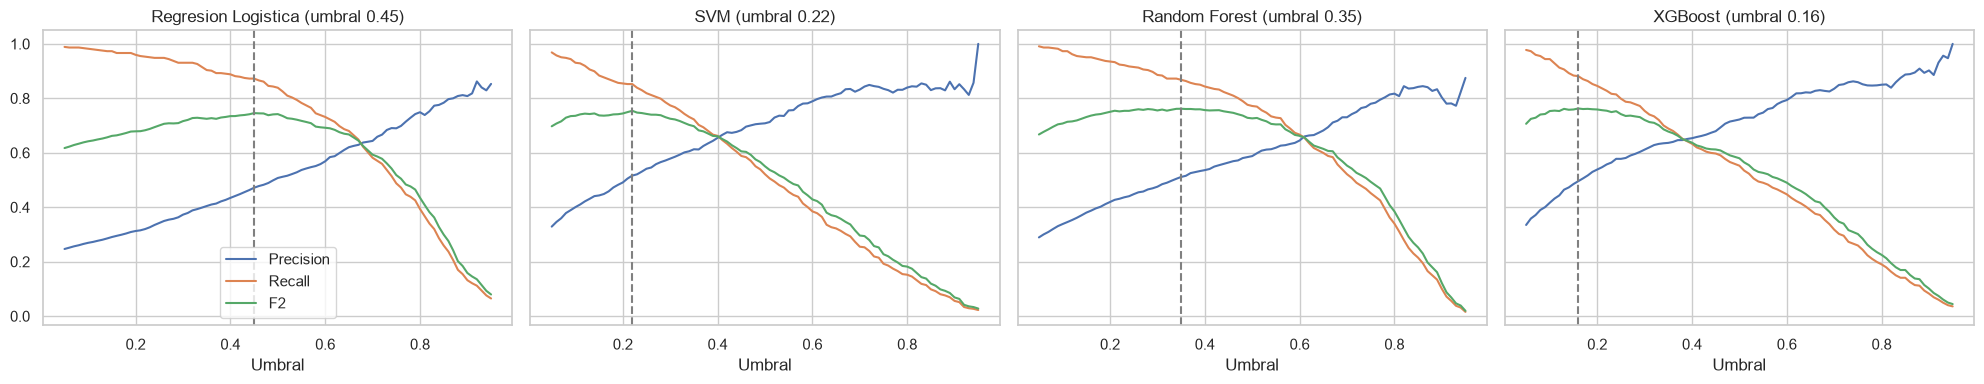

In [14]:
# Metricas segun el umbral para cada modelo (OOF en Train)
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, (nombre, proba) in zip(axes, oof.items()):
    ax.plot(umbrales, [precision_score(y_train, proba >= t, zero_division=0) for t in umbrales], label="Precision")
    ax.plot(umbrales, [recall_score(y_train, proba >= t) for t in umbrales], label="Recall")
    ax.plot(umbrales, [fbeta_score(y_train, proba >= t, beta=2) for t in umbrales], label="F2")
    ax.axvline(THRESHOLDS[nombre], color="gray", linestyle="--")
    ax.set_title(f"{nombre} (umbral {THRESHOLDS[nombre]})")
    ax.set_xlabel("Umbral")
axes[0].legend()
plt.tight_layout()
plt.show()

---
# Fase 6. Evaluacion final en Test

Los modelos se ajustan con todo Train y se evalua por primera y unica vez en Test, con el umbral de cada uno fijo desde la fase anterior.

In [15]:
# Ajuste final con todo Train
for nombre, m in mejores.items():
    m.fit(X_train, y_train)

proba_test = {nombre: m.predict_proba(X_test)[:, 1] for nombre, m in mejores.items()}

tabla_test = pd.DataFrame({n: {"Umbral": THRESHOLDS[n], **metricas(y_test, p, THRESHOLDS[n])}
                           for n, p in proba_test.items()}).T
display(tabla_test.round(3))

# Mismo resultado con el umbral estandar de 0.5, para ver cuanto aporta el umbral elegido
display(pd.DataFrame({n: metricas(y_test, p, 0.5) for n, p in proba_test.items()}).T
        [["Accuracy", "Precision", "Recall", "F1", "ROC AUC", "FP", "FN"]].round(3)
        .rename_axis("Umbral 0.5"))

,Umbral,Accuracy,Precision,Recall,F1,ROC AUC,TN,FP,FN,TP
Regresion Logistica,0.45,0.738,0.454,0.875,0.598,0.866,273.0,118.0,14.0,98.0
SVM,0.22,0.815,0.553,0.884,0.680,0.901,311.0,80.0,13.0,99.0
Random Forest,0.35,0.813,0.551,0.875,0.676,0.892,311.0,80.0,14.0,98.0
XGBoost,0.16,0.781,0.505,0.884,0.643,0.898,294.0,97.0,13.0,99.0


,Accuracy,Precision,Recall,F1,ROC AUC,FP,FN
Umbral 0.5,,,,,,,
Regresion Logistica,0.775,0.497,0.795,0.612,0.866,90.0,23.0
SVM,0.845,0.712,0.509,0.594,0.901,23.0,55.0
Random Forest,0.831,0.603,0.705,0.650,0.892,52.0,33.0
XGBoost,0.833,0.679,0.473,0.558,0.898,25.0,59.0


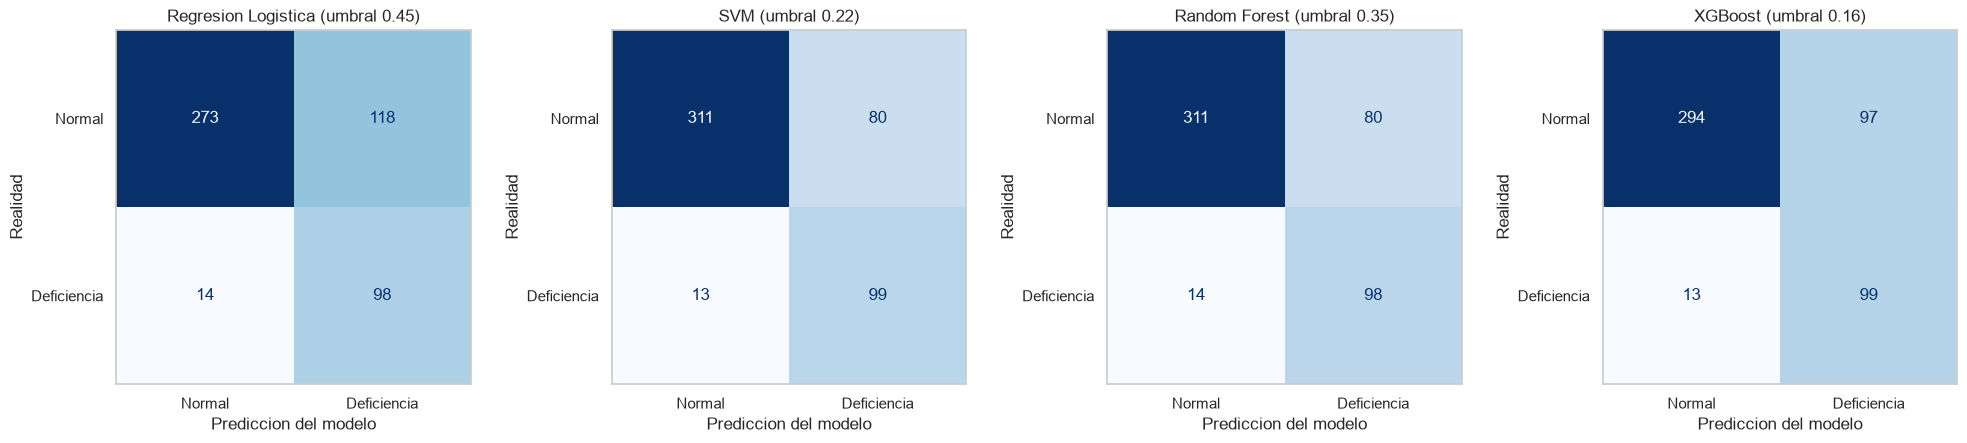

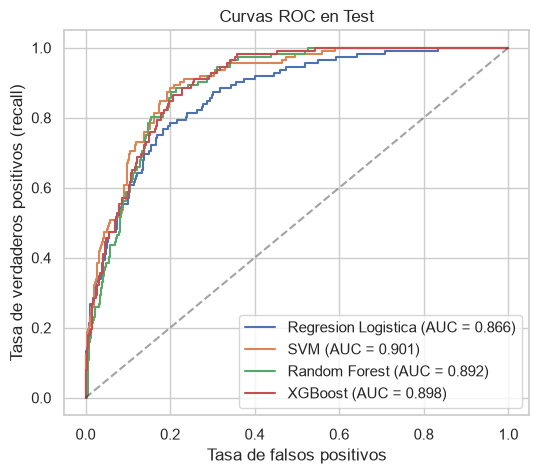

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (nombre, proba) in zip(axes, proba_test.items()):
    pred = (proba >= THRESHOLDS[nombre]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Normal", "Deficiencia"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.grid(False)
    ax.set_title(f"{nombre} (umbral {THRESHOLDS[nombre]})")
    ax.set_xlabel("Prediccion del modelo")
    ax.set_ylabel("Realidad")
plt.tight_layout()
plt.show()

# Curvas ROC en Test
plt.figure(figsize=(6, 5))
for nombre, proba in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curvas ROC en Test")
plt.legend()
plt.show()

**Análisis de la evaluación en Test**

En Test los cuatro modelos detectan a casi los mismos hombres con deficiencia, 98 o 99 de los 112, con 13 o 14 casos que se escapan, por lo que la diferencia está en las falsas alarmas, 80 en el SVM y en el Random Forest, 97 en XGBoost y 118 en la Regresión Logística. El mejor ROC AUC es el del SVM (0.901), seguido por XGBoost (0.898), Random Forest (0.892) y Regresión Logística (0.866), y el mejor F1 es de nuevo el del SVM (0.680), con Random Forest muy cerca (0.676), lo que coincide con la validación cruzada en que los tres modelos no lineales son casi equivalentes y la Regresión Logística queda claramente detrás en precisión (0.454 contra 0.55).

El umbral elegido es lo que hace que los modelos sean útiles, ya que con el umbral de 0.5 el recall de XGBoost cae de 0.884 a 0.473 y el del SVM de 0.884 a 0.509, es decir que dejarían escapar a la mitad de los casos.

Como las diferencias de ROC AUC entre SVM, XGBoost y Random Forest son menores a 0.01, elegir entre ellos depende más de la precisión y de la facilidad de uso que de la capacidad de ordenar a los pacientes.

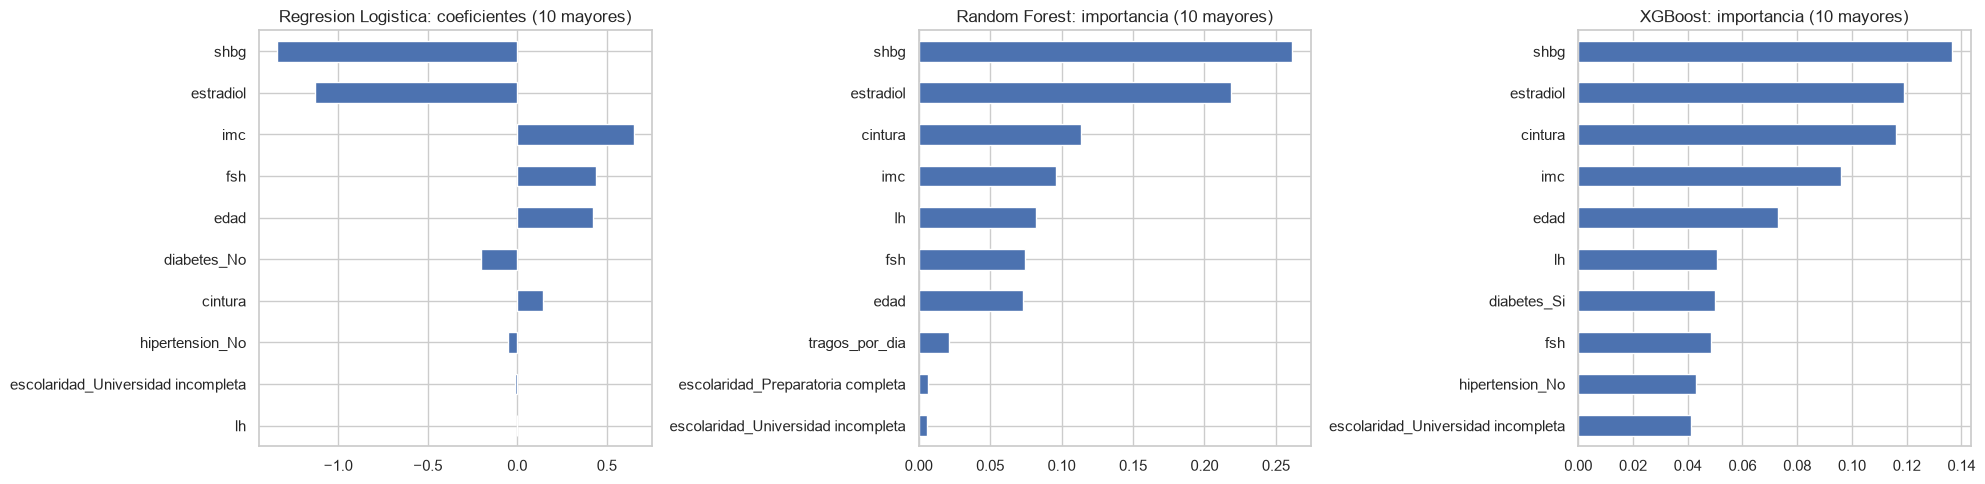

In [17]:
# Importancia de variables en los modelos de arboles y coeficientes de la regresion logistica
def nombres_features(pipe):
    return [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

coef = pd.Series(mejores["Regresion Logistica"].named_steps["modelo"].coef_[0],
                 index=nombres_features(mejores["Regresion Logistica"]))
coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).iloc[::-1].plot(kind="barh", ax=axes[0])
axes[0].set_title("Regresion Logistica: coeficientes (10 mayores)")

for ax, nombre in zip(axes[1:], ["Random Forest", "XGBoost"]):
    imp = pd.Series(mejores[nombre].named_steps["modelo"].feature_importances_, index=nombres_features(mejores[nombre]))
    imp.sort_values(ascending=False).head(10).iloc[::-1].plot(kind="barh", ax=ax)
    ax.set_title(f"{nombre}: importancia (10 mayores)")
plt.tight_layout()
plt.show()

**Análisis de la importancia de variables**

Los tres modelos coinciden en las variables más importantes, SHBG y estradiol, que ocupan el primer y segundo lugar tanto en Random Forest (0.26 y 0.22) como en XGBoost (0.14 y 0.12) y que en la Regresión Logística tienen los coeficientes más grandes y negativos (alrededor de -1.3 y -1.1), lo que significa que a menor SHBG y menor estradiol, mayor probabilidad de deficiencia. Después aparecen cintura, IMC y edad en los modelos de árboles, y en la Regresión Logística el IMC, la FSH y la edad tienen coeficientes positivos, es decir que más peso y más edad aumentan la probabilidad, mientras que la cintura casi no recibe coeficiente, seguramente porque se parece mucho al IMC (correlación de 0.92 en F_2).

Esto coincide con lo visto en el EDA de F_2, donde las variables más relacionadas con el objetivo eran cintura, IMC, SHBG y estradiol, y con la literatura clínica que relaciona la obesidad con testosterona baja.

La escolaridad y la raza aportan muy poco, ya que la raza ni siquiera aparece entre las 10 más importantes, por lo que la interfaz podría pedirlas como opcionales si se quisiera simplificar.

---
# Fase 7. Guardado de los modelos para la interfaz

Se guardan con `joblib` los cuatro Pipelines entrenados con Train, junto con un archivo JSON con los umbrales, las metricas, los hiperparametros y la informacion de cada variable (rango y valor tipico en Train, categorias validas) que la interfaz usa para armar sus campos.

In [18]:
ARCHIVOS = {"Regresion Logistica": "regresion_logistica.joblib", "SVM": "svm.joblib",
            "Random Forest": "random_forest.joblib", "XGBoost": "xgboost.joblib"}

for nombre, archivo in ARCHIVOS.items():
    # compress=3 reduce mucho el tamano del Random Forest sin cambiar sus predicciones
    joblib.dump(mejores[nombre], CARPETA_MODELOS / archivo, compress=3)

def a_json(v):
    # Convierte tipos de numpy y None a valores que JSON pueda guardar
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating,)): return float(v)
    return v

variables_numericas = {
    col: {"minimo": float(X_train[col].min()), "maximo": float(X_train[col].max()),
          "mediana": float(X_train[col].median()), "faltantes_en_train": int(X_train[col].isna().sum())}
    for col in num_cols
}
variables_categoricas = {
    col: {"opciones": list(etiquetas[col].values()), "moda": str(X_train[col].mode()[0])}
    for col in cat_cols
}

metadatos = {
    "version_sklearn": sklearn.__version__, "version_xgboost": xgboost.__version__,
    "semilla": RANDOM_STATE, "filas_train": int(len(X_train)), "filas_test": int(len(X_test)),
    "prevalencia_train": float(y_train.mean()),
    "orden_columnas": num_cols + cat_cols,
    "variables_numericas": variables_numericas,
    "variables_categoricas": variables_categoricas,
    "modelos": {
        nombre: {
            "archivo": ARCHIVOS[nombre],
            "umbral": THRESHOLDS[nombre],
            "hiperparametros": {k.replace("modelo__", ""): a_json(v) for k, v in grids[nombre].best_params_.items()},
            "roc_auc_cv": float(grids[nombre].cv_results_["mean_test_roc_auc"][grids[nombre].best_index_]),
            "metricas_test": {k: a_json(v) for k, v in metricas(y_test, proba_test[nombre], THRESHOLDS[nombre]).items()},
        } for nombre in ARCHIVOS
    },
}
with open(CARPETA_MODELOS / "metadatos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

display(pd.DataFrame({"Tamano (KB)": {a: round((CARPETA_MODELOS / a).stat().st_size / 1024, 1)
                                      for a in list(ARCHIVOS.values()) + ["metadatos.json"]}}))

,Tamano (KB)
regresion_logistica.joblib,2.3
svm.joblib,56.4
random_forest.joblib,1628.1
xgboost.joblib,38.8
metadatos.json,4.6


In [19]:
# Verificacion: se recargan los archivos y se comprueba que dan las mismas probabilidades en Test
for nombre, archivo in ARCHIVOS.items():
    recargado = joblib.load(CARPETA_MODELOS / archivo)
    igual = np.allclose(recargado.predict_proba(X_test)[:, 1], proba_test[nombre])
    print(f"{nombre}: probabilidades identicas tras recargar = {igual}")

# Ejemplo de uso como lo hara la interfaz: un solo hombre, con una variable vacia
ejemplo = pd.DataFrame([{
    "edad": 55, "imc": 33.0, "cintura": np.nan, "shbg": 25.0, "estradiol": 28.0, "lh": 3.5, "fsh": 5.0,
    "tragos_por_dia": 2, "diabetes": "Si", "hipertension": "Si", "fumador": "Si",
    "raza_etnia": "Blanco no hispano", "escolaridad": "Preparatoria completa",
}])[num_cols + cat_cols]
display(pd.DataFrame({n: {"Probabilidad": joblib.load(CARPETA_MODELOS / a).predict_proba(ejemplo)[0, 1],
                          "Umbral": THRESHOLDS[n]} for n, a in ARCHIVOS.items()}).T.round(3))

Regresion Logistica: probabilidades identicas tras recargar = True
SVM: probabilidades identicas tras recargar = True
Random Forest: probabilidades identicas tras recargar = True
XGBoost: probabilidades identicas tras recargar = True


,Probabilidad,Umbral
Regresion Logistica,0.619,0.45
SVM,0.372,0.22
Random Forest,0.754,0.35
XGBoost,0.419,0.16


---
# Fase 8. Conclusiones

Se entrenaron los cuatro modelos pedidos con el mismo procedimiento de F_1 y F_2, y los cuatro quedaron guardados en la carpeta `modelos/` junto con sus umbrales y metadatos, listos para usarse desde la interfaz en Streamlit (`app.py`). Los resultados de la Regresión Logística (ROC AUC de 0.866 en Test, con 118 falsos positivos y 14 falsos negativos) y del SVM (0.901) coinciden con los reportados en F_1 y F_2, lo que confirma que la partición, el preprocesamiento y la semilla son los mismos.

El SVM obtuvo el mejor resultado en Test (ROC AUC de 0.901 y F1 de 0.680), pero XGBoost y Random Forest quedaron a menos de 0.01 de ROC AUC, una diferencia menor que la desviación entre folds, por lo que no se puede decir que uno sea claramente mejor que los otros dos. La Regresión Logística fue el modelo más débil, sobre todo en precisión, aunque tiene la ventaja de ser el más fácil de interpretar. Los modelos no lineales solo mejoran un poco al lineal, lo que confirma que la relación entre las variables y la deficiencia es principalmente lineal y suave, con SHBG, estradiol, cintura, IMC y edad como las variables más importantes en los tres tipos de modelo.

La limitación principal es que con el recall cerca de 0.88 la precisión queda entre 45% y 55%, por lo que casi la mitad de las alertas serían falsas alarmas, lo que es aceptable para una herramienta de apoyo que solo sugiere confirmar con un análisis de sangre, pero no para un diagnóstico ni para un tamizaje de la población general. Además, los modelos se entrenaron solo con Train para conservar válidas las métricas de Test, por lo que una versión final podría reentrenarse con todos los datos.

Para el proyecto final lo recomendable es mostrar los cuatro modelos en la interfaz y comparar su coincidencia, ya que cuando los cuatro marcan posible deficiencia la señal es más confiable que cuando solo uno lo hace.